# 07 — Explainability

This notebook explains what drives the h=24 champion's forecast: permutation importance (single and by family, and across horizons), partial dependence and ALE for temperature, SHAP for the whole holdout and for the single worst prediction, and a shallow tree that describes notebook 05's regimes. None of it is causal: it describes the fitted model, not what an intervention would do.

**Inputs:** `panel.parquet`, `best_params.json`, `nb04` (holdout MAE, per-horizon champions), `nb05` (regime labels and names).
**Outputs:** ledger block `nb07`; figures `07_permutation`, `07_importance_by_horizon`, `07_pdp_ice`, `07_shap`, `07_cluster_tree`.

### 7.1 — Refit the winning pipeline

Refit the champion from `best_params.json` on `dev` and predict `hold`, so the explanations are about the model actually reported. The holdout MAE should match `nb04/holdout_mae`.

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as cfg
from src import results as R

pd.set_option("display.width", 140, "display.max_columns", 50)
plt.rcParams["figure.figsize"] = cfg.FIGSIZE
plt.rcParams["figure.dpi"] = cfg.DPI
np.random.seed(cfg.SEED)

from src import features as P
from src import explain as E
from sklearn.metrics import mean_absolute_error

# THE CHAMPION, NOT A CONVENIENT RETRAINED VARIANT. This cell used to build a
# default pipeline on notebook 01's `chosen_lags` -- the h=1 set -- and never opened
# best_params.json at all, so notebook 07 was explaining an h=1 model with
# untuned hyperparameters and printing a holdout MAE of 643.7 against the
# champion's 2,246.6 at the time (2,159.6 now, as printed below). The markdown above already said to load best_params.json;
# the code did not. Explainability computed on a different model than the one
# reported is worse than no explainability, because it looks like evidence.
BP = json.loads(cfg.BEST_PARAMS.read_text())
PARAMS, HORIZON = BP["params"], BP["horizon"]
LAGS = tuple(PARAMS["lag__lags"])
print(f"champion: h={HORIZON}, lags={LAGS}, cv_mae={BP['cv_mae']:,.1f}")

df = pd.read_parquet(cfg.PANEL).sort_values([cfg.TIME_COL, cfg.GROUP_COL])
cut = cfg.HOLDOUT_CUT
dev, hold = df[df[cfg.TIME_COL] <= cut], df[df[cfg.TIME_COL] > cut]

pipe = P.make_supervised_pipeline(cfg.NUMERIC_FEATURES, lags=LAGS)
pipe.set_params(**PARAMS)
pipe.fit(dev, dev[cfg.TARGET])

pred = pipe.predict(hold)
mae = float(mean_absolute_error(hold[cfg.TARGET], pred))
reported = R.require("nb04", "holdout_mae")
print(f"holdout MAE here {mae:,.1f} | notebook 04 reported {reported:,.1f} "
      f"| difference {mae - reported:+,.1f}")
assert abs(mae - reported) < 1.0, (
    f"this is not the reported model: {mae:,.1f} vs {reported:,.1f}. "
    "Explaining a different fit than the one in the report is the defect this "
    "assertion exists to prevent.")

# The worst day is computed here: the worst complete (region, UTC day). It is not
# notebook 04's `failure_analysis.worst_day`, which is the worst UTC date averaged over
# all six regions (2024-07-02). An earlier version read a `worst_day` key notebook 04
# never wrote and saved the STRING "None".
WORST = E.worst_day(hold, hold[cfg.TARGET].to_numpy(), pred)
print(f"worst day: {WORST['zone']} {WORST['date']} "
      f"MAE {WORST['mae_mw']:,.1f} MW over {WORST['n_hours']} h")

Xh = E.transformed_holdout(pipe, hold)
model = pipe.named_steps["model"]
yh = hold[cfg.TARGET].to_numpy()
assert len(Xh) == len(hold), (
    f"transform changed the row count ({len(Xh)} vs {len(hold)}); every "
    "alignment below assumes it does not")
print(f"model input: {Xh.shape[0]:,} rows x {Xh.shape[1]} selected features")

champion: h=24, lags=(24, 25, 26, 48, 168), cv_mae=2,107.3


holdout MAE here 2,159.6 | notebook 04 reported 2,159.6 | difference +0.0
worst day: MISO 2024-07-03 MAE 19,681.4 MW over 24 h


model input: 47,299 rows x 57 selected features


### 7.2 — Permutation importance, single and grouped

Shuffle each feature on the held-out data and measure the MAE increase in MW; then shuffle whole families together. Held-out data is used because importance is a claim about forecasting, not about fitting.

baseline holdout MAE 2,159.6 MW

top 12 single features (MW of MAE increase when permuted)
             feature    family mae_increase_mw sd_mw
      net_load_lag24       lag         8,983.2  40.9
        demand_lag24 exogenous         3,597.6  12.4
        zone_is_MISO      zone           798.3   5.9
          wind_lag24 exogenous           547.2   5.0
     net_load_lag168       lag           532.0   4.7
     wind_speed_100m   weather           521.8   4.0
      net_load_lag48       lag           353.0   5.1
net_load_roll24_mean   rolling           329.5   5.3
         solar_lag24 exogenous           194.3   2.2
       apparent_temp   weather           187.3   1.8
       nuclear_lag24 exogenous           183.6   3.3
            pressure   weather           134.7   3.0

by family
   family  n_features mae_increase_mw sum_of_singles_mw max_single_mw ratio_grouped_over_sum  n_free_riders
      lag           5        11,416.2           9,880.9       8,983.2                   1.16         

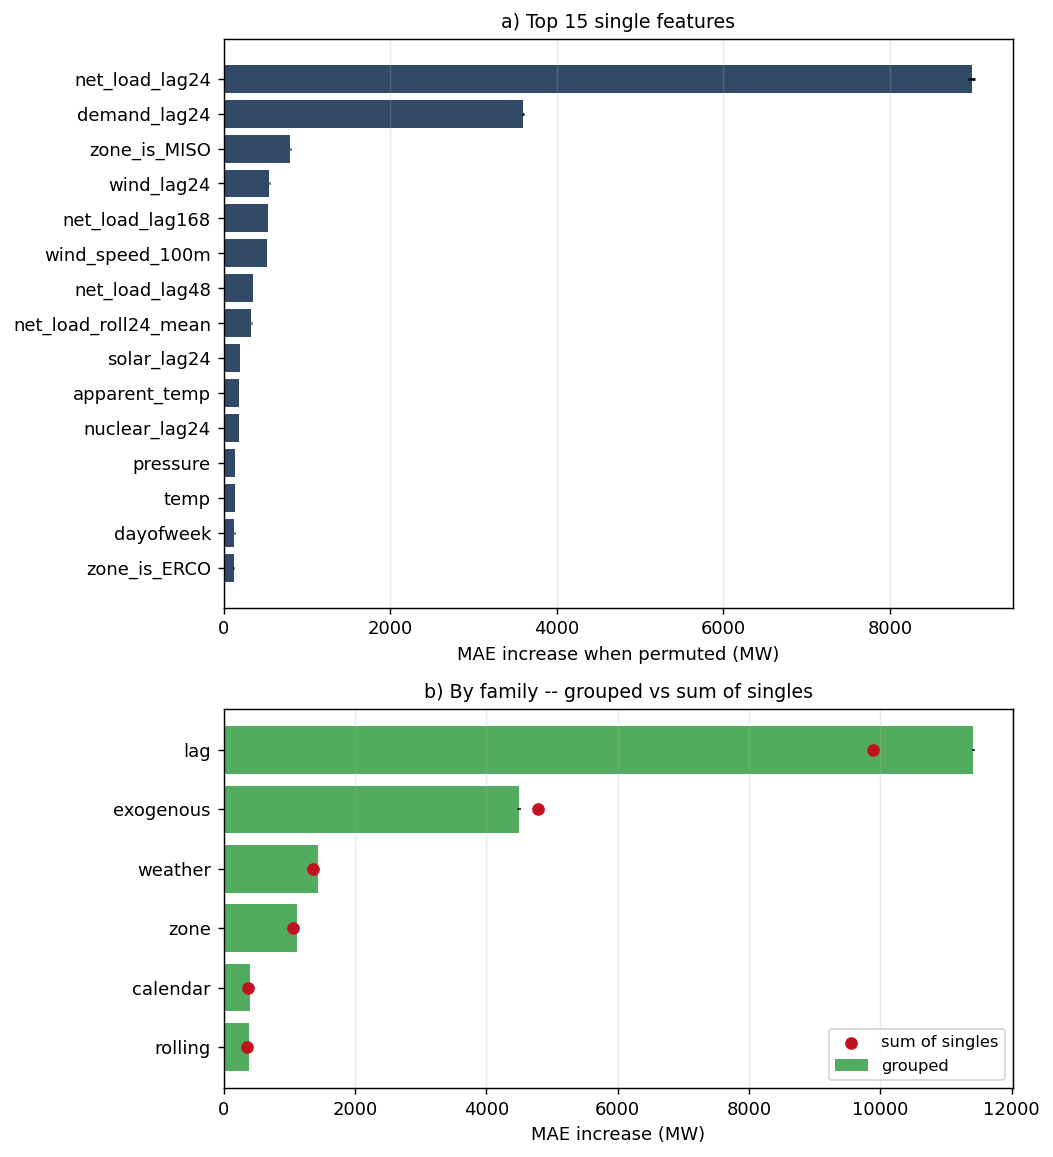

In [2]:
# WHAT: permutation importance per feature, then per FAMILY, both in MW of MAE
#       increase on the held-out block.
# WHY:  permutation is computed on HELD-OUT data because importance is a claim
#       about generalisation. On training data a model that memorised a column
#       would score it as vital, which is the opposite of what we are asking.
# NOTE: this runs against the TRANSFORMED matrix and the fitted estimator, not
#       the raw frame through the pipeline. The lag step rebuilds history by
#       timestamp lookup on every call, so permuting through the pipeline would
#       pay for a full reconstruction on each of the ~300 repeats; and the names
#       that come back are `select.selected_`, which is what every plot here and
#       in the SHAP section is labelled with.
single = E.permutation_single(model, Xh, yh, n_repeats=5, seed=cfg.SEED)
grouped = E.permutation_grouped(model, Xh, yh, n_repeats=5, seed=cfg.SEED)
gap = E.redundancy_gap(single, grouped)

print(f"baseline holdout MAE {single.attrs['baseline_mae']:,.1f} MW\n")
print("top 12 single features (MW of MAE increase when permuted)")
print(single.head(12).to_string(index=False,
      formatters={"mae_increase_mw": "{:,.1f}".format, "sd_mw": "{:,.1f}".format}))
print("\nby family")
print(gap[["family", "n_features", "mae_increase_mw", "sum_of_singles_mw",
           "max_single_mw", "ratio_grouped_over_sum", "n_free_riders"]].to_string(
      index=False, formatters={"mae_increase_mw": "{:,.1f}".format,
                               "sum_of_singles_mw": "{:,.1f}".format,
                               "max_single_mw": "{:,.1f}".format,
                               "ratio_grouped_over_sum": "{:.2f}".format}))

# THE SCAFFOLD'S READING RULE IS WRONG AND THIS PRINTS THE REFUTATION. 7.2 says
# "where grouped >> sum of singles, the features are redundant substitutes".
# Permutation acts at PREDICT time on a model that is already fitted, so there is
# no recovery through the twin -- the trees are built. If the fit leaned on one of
# two duplicates, the other scores ~0 alone and grouped simply equals the used
# one, so the two columns agree. Verified on exact and near duplicates across
# RandomForest, HistGradientBoosting and Ridge: the ratio is ~1.00 every time
# (tests/test_explain.py pins it). The diagnostic that DOES work is the free
# rider: a column scoring ~0 alone inside a family that matters.
r = gap["ratio_grouped_over_sum"].dropna()
print(f"\ngrouped/sum ratio across families: min {r.min():.2f}, max {r.max():.2f}"
      f" -- flat, as predicted; it does not detect redundancy")
free = single.merge(gap[["family", "mae_increase_mw"]].rename(
    columns={"mae_increase_mw": "family_mw"}), on="family")
free = free[(free["mae_increase_mw"] < 0.05 * free["family_mw"]) & (free["family_mw"] > 1)]
print(f"free riders (single < 5% of their family): {len(free)} of {len(single)}")
if len(free):
    print(free[["feature", "family", "mae_increase_mw", "family_mw"]].head(10).to_string(
        index=False, formatters={"mae_increase_mw": "{:,.1f}".format,
                                 "family_mw": "{:,.1f}".format}))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.2, 9.0),
                               gridspec_kw={"height_ratios": [1.5, 1]})
top = single.head(15).iloc[::-1]
ax1.barh(top["feature"], top["mae_increase_mw"],
         xerr=top["sd_mw"], color="#1d3557", alpha=0.9)
ax1.set_xlabel("MAE increase when permuted (MW)")
ax1.set_title("a) Top 15 single features", fontsize=10.5)
ax1.grid(alpha=0.25, axis="x")

g = grouped.iloc[::-1]
ax2.barh(g["family"], g["mae_increase_mw"], xerr=g["sd_mw"],
         error_kw={"lw": 1.1, "ecolor": "#333"},
         color="#3fa34d", alpha=0.9, label="grouped")
ax2.scatter(g["mae_increase_mw"].where(g["family"].isin(gap["family"])),
            range(len(g)), s=0)
sums = gap.set_index("family")["sum_of_singles_mw"]
ax2.scatter([sums.get(f, np.nan) for f in g["family"]], range(len(g)),
            color="#c1121f", zorder=3, label="sum of singles")
ax2.set_xlabel("MAE increase (MW)")
ax2.set_title("b) By family -- grouped vs sum of singles", fontsize=10.5)
ax2.legend(fontsize=9); ax2.grid(alpha=0.25, axis="x")
plt.tight_layout()
plt.savefig(cfg.FIGURES / "07_permutation.png", bbox_inches="tight")
plt.show()

**Figure: `07_permutation.png`**

**What this shows:** (a) MAE increase when each feature is shuffled; (b) the same for whole families, with the sum of the family's single scores marked.

**What I see:** Against a baseline MAE of 2,159.6 MW, shuffling `net_load_lag24` (yesterday's net load at the same hour) costs 8,983 MW and `demand_lag24` 3,598 MW; the next is `zone_is_MISO` at 798. By family: lag 11,416 MW, exogenous 4,500, weather 1,433, zone 1,111, calendar 400, rolling 394. Grouped over summed singles runs 0.94 to 1.16, so grouping does not reveal redundancy: permutation acts on an already-fitted model, so no column can cover for another. 37 of 57 features are free riders (under 5% of their family's score). The exogenous family is mostly `demand_lag24` (80% of it).

**What it means:** This is a persistence model with corrections. Notebook 04's ablation (refit without a family) ranks families very differently: lag 11,416 MW here vs +66 MW there, weather 1,433 vs +698. Both are right: on refit the model rebuilds net-load history from demand, wind and solar lags, since `net_load_lag24 = demand_lag24 − wind_lag24 − solar_lag24` exactly. Weather is the family a refit cannot rebuild.

**What I do:** Use permutation for "what does this model use" and ablation for "what would we lose without this data". Never quote the exogenous bar as a solar or wind result. The free riders are candidates for removal, which is an ablation question.

### 7.2b — Importance across horizons

Grouped permutation importance at h = 1, 24, 48 and 72, each on that horizon's champion, shown as each family's share and in MW. Notebook 01's prediction P5 says temperature's share rises with the horizon; it is tested here on the whole weather family. The reason to expect it: a lag `L` is only allowed if `L ≥ h`, so at long horizons the fresh lags disappear and the weather of the target hour must fill in. Share and MW are both shown because total error grows from 547 to 2,471 MW between h=1 and h=72.

h= 1  baseline MAE    547.1 MW   weather    177.3 MW  lag 19,512.6 MW


h=24  baseline MAE  2,159.6 MW   weather  1,432.7 MW  lag 11,416.2 MW


h=48  baseline MAE  2,389.7 MW   weather  1,704.5 MW  lag  8,155.6 MW


h=72  baseline MAE  2,470.8 MW   weather  1,822.9 MW  lag  7,052.2 MW

--- share of total permutation importance, by family and horizon ---


horizon,1,24,48,72
family,,,,
calendar,2.6,2.1,3.2,3.8
exogenous,1.7,23.4,34.0,33.1
lag,93.9,59.3,42.9,39.9
rolling,0.8,2.0,1.9,2.1
weather,0.9,7.4,9.0,10.3
zone,0.2,5.8,9.0,10.8



--- the same in MW of holdout MAE increase ---


horizon,1,24,48,72
family,,,,
calendar,534.2,399.5,616.4,676.9
exogenous,352.2,4500.5,6461.9,5858.2
lag,19512.6,11416.2,8155.6,7052.2
rolling,165.4,393.6,359.5,371.2
weather,177.3,1432.7,1704.5,1822.9
zone,35.6,1110.6,1703.1,1906.5



PREDICTION P5 — 'temperature's share rises with the horizon', tested on the weather family
   weather SHARE by horizon: {1: 0.9, 24: 7.4, 48: 9.0, 72: 10.3} %   monotone: True
   weather MW    by horizon: {1: 177.3, 24: 1432.7, 48: 1704.5, 72: 1822.9} MW   monotone: True
   lag SHARE     by horizon: {1: 93.9, 24: 59.3, 48: 42.9, 72: 39.9} %
   VERDICT: P5 HOLDS for the weather family on both readings

--- the six strongest weather columns at each horizon, with their rank among ALL features ---


horizon,1,24,48,72
feature,,,,
apparent_temp,23,10,8,8
dhi,16,<NA>,<NA>,<NA>
ghi,18,<NA>,<NA>,<NA>
ghi_lag24,13,<NA>,<NA>,<NA>
pressure,24,12,18,16
temp,<NA>,13,16,14
temp_lag24,22,18,<NA>,<NA>
temp_lag48,<NA>,<NA>,19,<NA>
temp_lag72,<NA>,<NA>,<NA>,21


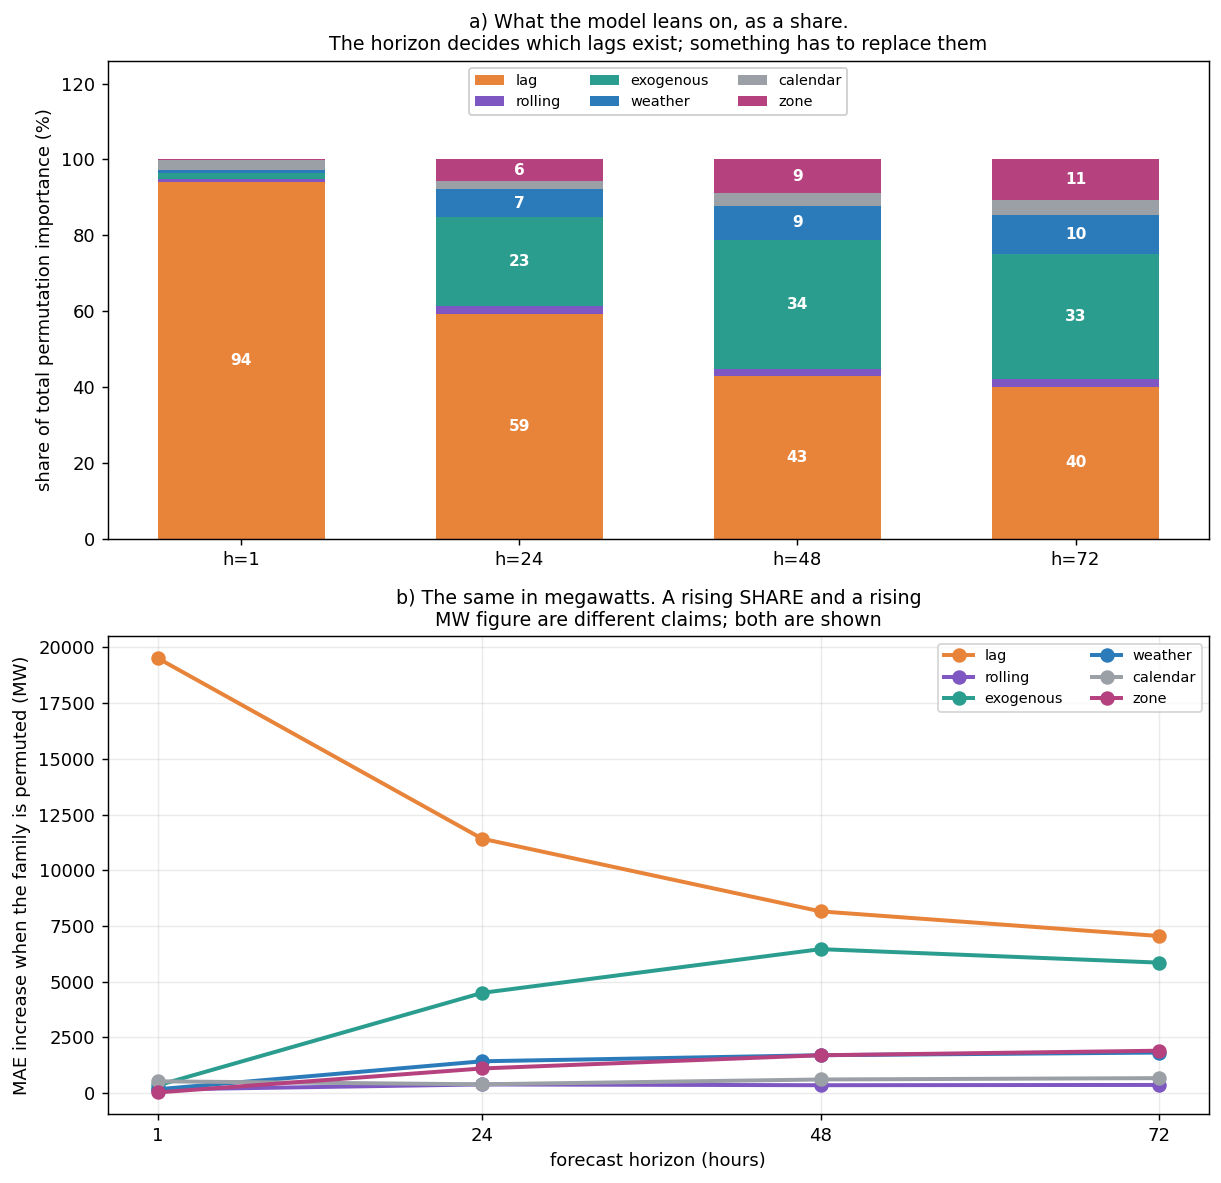

In [3]:
# WHAT: grouped permutation importance at every horizon, on each horizon's own
#       champion, as a share of the total and in megawatts.
# WHY:  prediction P5 (registered as temperature's share) is tested on the whole weather
#       family: it should rise with the horizon because the admissible lags decay. This is the direct test, and it is only worth running
#       now that the weather family is 23 columns rather than 4.
# COST: four fits plus four permutation passes over the holdout. The permutation is
#       on the TRANSFORMED matrix and the fitted estimator, as in 7.2, so the lag
#       step is not rebuilt on every repeat.
from sklearn.ensemble import HistGradientBoostingRegressor

per_h = R.require("nb04", "per_horizon_champions")
rows_h, single_h = [], {}
for h in cfg.HORIZONS:
    ch = per_h[str(h)]["params"]
    mp = {k.replace("model__", ""): v for k, v in ch.items() if k.startswith("model__")}
    pipe_h = P.make_supervised_pipeline(
        cfg.NUMERIC_FEATURES, lags=tuple(ch["lag__lags"]),
        roll_windows=tuple(ch["lag__roll_windows"]), k=ch["select__k"],
        model=HistGradientBoostingRegressor(random_state=cfg.SEED, **mp))
    pipe_h.fit(dev, dev[cfg.TARGET])
    Xh_h = E.transformed_holdout(pipe_h, hold)
    mdl_h = pipe_h.named_steps["model"]
    g_h = E.permutation_grouped(mdl_h, Xh_h, yh, n_repeats=5, seed=cfg.SEED)
    s_h = E.permutation_single(mdl_h, Xh_h, yh, n_repeats=5, seed=cfg.SEED)
    single_h[h] = s_h
    base = float(g_h.attrs.get("baseline_mae", np.nan))
    total = float(g_h["mae_increase_mw"].clip(lower=0).sum())
    for _, r in g_h.iterrows():
        rows_h.append({"horizon": h, "family": r["family"],
                       "mae_increase_mw": float(r["mae_increase_mw"]),
                       "share": float(max(r["mae_increase_mw"], 0) / total)
                       if total > 0 else np.nan,
                       "baseline_mae": base})
    print(f"h={h:>2}  baseline MAE {base:8,.1f} MW   "
          f"weather {float(g_h.set_index('family')['mae_increase_mw'].get('weather', 0)):8,.1f} MW"
          f"  lag {float(g_h.set_index('family')['mae_increase_mw'].get('lag', 0)):8,.1f} MW")

ph = pd.DataFrame(rows_h)
share = ph.pivot(index="family", columns="horizon", values="share").fillna(0)
mw = ph.pivot(index="family", columns="horizon", values="mae_increase_mw").fillna(0)
print("\n--- share of total permutation importance, by family and horizon ---")
display((100 * share).round(1))
print("\n--- the same in MW of holdout MAE increase ---")
display(mw.round(1))

# --- P5, tested on both readings -------------------------------------------
w_share = share.loc["weather"] if "weather" in share.index else None
w_mw = mw.loc["weather"] if "weather" in mw.index else None
l_share = share.loc["lag"] if "lag" in share.index else None
p5_share = bool(w_share is not None and w_share.is_monotonic_increasing)
p5_mw = bool(w_mw is not None and w_mw.is_monotonic_increasing)
print(f"\nPREDICTION P5 — 'temperature's share rises with the horizon', tested on the weather family")
if w_share is not None:
    print(f"   weather SHARE by horizon: "
          f"{ {int(k): round(100*v, 1) for k, v in w_share.items()} } %   "
          f"monotone: {p5_share}")
    print(f"   weather MW    by horizon: "
          f"{ {int(k): round(v, 1) for k, v in w_mw.items()} } MW   monotone: {p5_mw}")
    print(f"   lag SHARE     by horizon: "
          f"{ {int(k): round(100*v, 1) for k, v in l_share.items()} } %")
    # P5 was registered for temperature; it is scored on the weather FAMILY, because
    # temperature's importance is shared with its correlated weather twins (say so)
    verdict = ("HOLDS for the weather family on both readings" if (p5_share and p5_mw) else
               "HOLDS for the weather family on share only" if p5_share else
               "HOLDS for the weather family in megawatts only" if p5_mw else
               "FAILS — weather does not climb, so the long-horizon model is not "
               "substituting weather for lags; its extra error is unexplained "
               "rather than reallocated, which is the more interesting outcome and "
               "is reported as such")
    print(f"   VERDICT: P5 {verdict}")
else:
    verdict = "no weather family survived selection at any horizon"
    print(f"   {verdict}")

# --- which individual weather columns do the climbing? ----------------------
climb = []
for h in cfg.HORIZONS:
    s_h = single_h[h]
    wf = s_h[s_h["family"] == "weather"].head(6)
    for _, r in wf.iterrows():
        climb.append({"horizon": h, "feature": r["feature"],
                      "mae_increase_mw": float(r["mae_increase_mw"]),
                      "rank_overall": int(s_h.index.get_loc(r.name)) + 1})
cl = pd.DataFrame(climb)
if len(cl):
    print("\n--- the six strongest weather columns at each horizon, with their "
          "rank among ALL features ---")
    display(cl.pivot_table(index="feature", columns="horizon",
                           values="rank_overall").astype("Int64"))

fig, axes = plt.subplots(2, 1, figsize=(9.5, 9.2))
ax = axes[0]
bottom = np.zeros(len(share.columns))
COLS = {"lag": "#e8833a", "rolling": "#7e57c2", "weather": "#2b7bba",
        "calendar": "#9aa0a6", "exogenous": "#2a9d8f", "zone": "#b5417f",
        "other": "#cccccc"}
order = [f for f in ["lag", "rolling", "exogenous", "weather", "calendar", "zone",
                     "other"] if f in share.index]
xs = np.arange(len(share.columns))
for fam in order:
    vals = 100 * share.loc[fam].to_numpy()
    ax.bar(xs, vals, 0.6, bottom=bottom, label=fam, color=COLS.get(fam, "#888"))
    for j, v in enumerate(vals):
        if v > 4:
            ax.text(xs[j], bottom[j] + v / 2, f"{v:.0f}", ha="center", va="center",
                    fontsize=8.5, color="white", fontweight="bold")
    bottom += vals
ax.set_xticks(xs); ax.set_xticklabels([f"h={h}" for h in share.columns])
ax.set_ylabel("share of total permutation importance (%)")
ax.set_title("a) What the model leans on, as a share.\nThe horizon decides which "
             "lags exist; something has to replace them", fontsize=10.5)
ax.set_ylim(0, 126)  # headroom so the legend never covers a bar segment label
ax.legend(fontsize=8, ncol=3, loc="upper center", framealpha=0.95)

ax = axes[1]
for fam in order:
    ax.plot(list(mw.columns), mw.loc[fam], "o-", lw=2.2, ms=7,
            color=COLS.get(fam, "#888"), label=fam)
ax.set_xticks(list(mw.columns)); ax.set_xlabel("forecast horizon (hours)")
ax.set_ylabel("MAE increase when the family is permuted (MW)")
ax.set_title("b) The same in megawatts. A rising SHARE and a rising\nMW figure are "
             "different claims; both are shown", fontsize=10.5)
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "07_importance_by_horizon.png", bbox_inches="tight")
plt.show()

R.save("nb07", {"importance_by_horizon": {
    "share": {str(h): {f: float(share.loc[f, h]) for f in share.index}
              for h in share.columns},
    "mae_increase_mw": {str(h): {f: float(mw.loc[f, h]) for f in mw.index}
                        for h in mw.columns},
    "weather_share_monotone": p5_share,
    "weather_mw_monotone": p5_mw,
    "p5_verdict": verdict,
    "weather_feature_ranks": (cl.to_dict("records") if len(cl) else []),
}});


**Figure: `07_importance_by_horizon.png`**

**What I see:** The weather family's share rises from 0.9% at h=1 to 7.4%, 9.0% and 10.3% at h=24, 48 and 72, and it rises in MW too. The lag family's share falls from 93.9% to 59.3%, 42.9% and 39.9%. Verdict: P5 **holds for the weather family on both readings**.

**What it means:** As the admissible lags get older, the model leans more on weather. Permutation measures how much the fitted model uses a family, not what the family is worth to remove, so it can disagree with ablation.

**What I do:** Store the verdict as `p5_verdict`.

### 7.3 — Partial dependence and ICE

PDP and ICE curves for temperature and `hour_sin`, plus ALE for temperature. The model should have learned a U-shaped temperature response (heating and cooling), which notebook 01's linear correlation could not show. ALE is added because PDP evaluates impossible combinations (e.g. very cold hours with summer solar).

PDP/ICE for: ['temp', 'hour_sin']


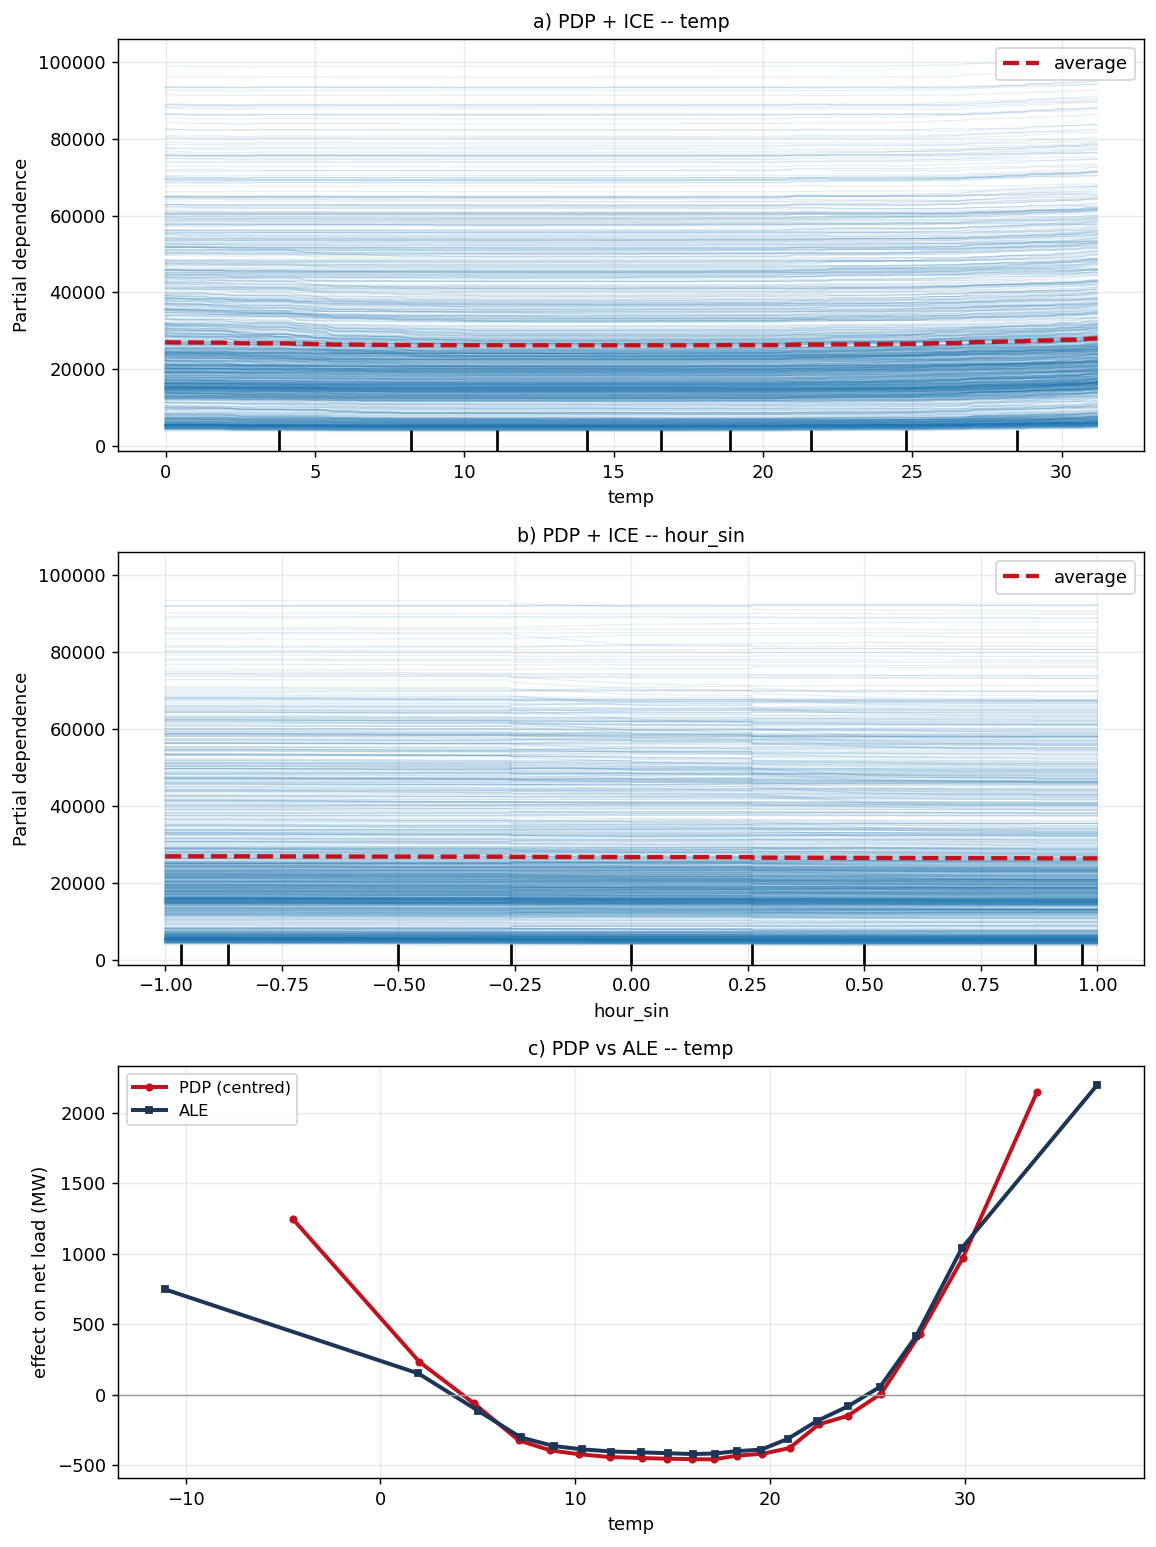

compared over 1.9 to 29.9 C, where both curves are evaluated
temp: PDP spans 1,416 MW, ALE spans 1,460 MW; largest gap between the curves 122 MW

ALE and centred PDP of temp by bin (MW):
 temp  ale_mw  pdp_mw
-11.1   747.0     NaN
  1.9   151.6   242.0
  5.0  -111.7   -83.7
  7.2  -301.8  -327.5
  8.9  -362.7  -396.9
 10.4  -386.1  -423.1
 11.8  -401.7  -441.1
 13.4  -407.4  -447.7
 14.8  -413.7  -452.7
 16.0  -419.6  -455.8
 17.2  -415.8  -456.5
 18.3  -399.0  -430.9
 19.5  -388.1  -418.5
 20.9  -312.5  -380.0
 22.4  -186.0  -220.5
 24.0   -81.4  -147.4
 25.6    57.0     3.6
 27.5   416.3   390.7
 29.8  1040.7   959.2
 36.8  2197.0     NaN


In [4]:
# WHAT: partial dependence with ICE for two features, and ALE beside PDP for the
#       one where they are most likely to disagree.
# WHY:  PDP averages the model over the MARGINAL distribution of everything else,
#       so it evaluates combinations that never occur -- hour 20 at peak solar,
#       January at 35 degrees. On this panel those combinations are not rare
#       edge cases, they are most of the joint space. ALE asks a local question
#       instead: inside a narrow bin of the feature, how far does the prediction
#       move when the feature is nudged across the bin, holding each row's own
#       other features fixed. Where the two disagree, trust ALE.
from sklearn.inspection import PartialDependenceDisplay

SUB = min(4000, len(Xh))
rs = np.random.default_rng(cfg.SEED)
sub_idx = rs.choice(len(Xh), SUB, replace=False)
Xsub = Xh.iloc[sub_idx]

wanted = [c for c in ("temp", "hour_sin", "cloud_cover", "net_load_lag24")
          if c in Xh.columns][:2]
print("PDP/ICE for:", wanted)

fig, axes = plt.subplots(3, 1, figsize=(9.0, 12.0))
PartialDependenceDisplay.from_estimator(
    model, Xsub, features=[Xh.columns.get_loc(w) for w in wanted],
    feature_names=list(Xh.columns), kind="both", ax=axes[:2],
    ice_lines_kw={"alpha": 0.12, "linewidth": 0.6},
    pd_line_kw={"color": "#c1121f", "linewidth": 2.4})
# Panel letter from the loop index. Building it as a literal "a)" inside the
# loop gave the figure two panels called "a)" and no "b)".
for _panel, (ax, w) in enumerate(zip(axes[:2], wanted)):
    ax.set_title(f"{'ab'[_panel]}) PDP + ICE -- {w}", fontsize=10.5)
    ax.grid(alpha=0.25)

focus = wanted[0]
ale = E.ale_1d(model, Xsub, focus, n_bins=20)
pdp_x = np.quantile(Xsub[focus], np.linspace(0.02, 0.98, 20))
pdp_y = []
for v in pdp_x:
    tmp = Xsub.copy(); tmp[focus] = v
    pdp_y.append(float(model.predict(tmp).mean()))
pdp_y = np.array(pdp_y) - np.mean(pdp_y)

axes[2].plot(pdp_x, pdp_y, color="#c1121f", lw=2.2, marker="o", ms=3.5, label="PDP (centred)")
axes[2].plot(ale["x"], ale["ale"], color="#1d3557", lw=2.2, marker="s", ms=3.5, label="ALE")
axes[2].axhline(0, color="0.6", lw=0.8)
axes[2].set_xlabel(focus); axes[2].set_ylabel("effect on net load (MW)")
axes[2].set_title(f"c) PDP vs ALE -- {focus}", fontsize=10.5)
axes[2].legend(fontsize=9); axes[2].grid(alpha=0.25)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "07_pdp_ice.png", bbox_inches="tight")
plt.show()

# Compared only where BOTH curves exist: the PDP is evaluated on the 2nd-98th percentile
# of temperature, the ALE on the full range, and interpolating the PDP outside its grid
# would just repeat its end values. Each curve is centred over that common range, so the
# gap measures shape, not the two methods' different centring conventions.
_in = ((ale["x"] >= pdp_x.min()) & (ale["x"] <= pdp_x.max())).to_numpy()
_ax, _a = ale["x"].to_numpy()[_in], ale["ale"].to_numpy()[_in]
_p = np.interp(_ax, pdp_x, pdp_y)
disagreement = float(np.max(np.abs((_p - _p.mean()) - (_a - _a.mean()))))
pdp_range = float(_p.max() - _p.min())
ale_range = float(_a.max() - _a.min())
print(f"compared over {_ax.min():.1f} to {_ax.max():.1f} C, where both curves are evaluated")
print(f"{focus}: PDP spans {pdp_range:,.0f} MW, ALE spans {ale_range:,.0f} MW; "
      f"largest gap between the curves {disagreement:,.0f} MW")
print(f"\nALE and centred PDP of {focus} by bin (MW):")
print(pd.DataFrame({focus: ale["x"].to_numpy(), "ale_mw": ale["ale"].to_numpy(),
                    "pdp_mw": np.where(_in, np.interp(ale["x"], pdp_x, pdp_y), np.nan)}
                   ).round(1).to_string(index=False))

**Figure: `07_pdp_ice.png`**

**What this shows:** (a) ICE curves (one per hour) and their average (PDP) for temperature; (b) the same for `hour_sin`; (c) ALE against centred PDP for temperature.

**What I see:** The ICE lines are almost flat, at levels set mostly by region size. `hour_sin` is essentially flat. In (c) the response is a clear U: high when very cold, lowest around 16 °C, and highest in the heat. Over 1.9 to 29.9 °C ALE spans 1,460 MW and PDP 1,416 MW; they agree in the middle and separate at the extremes, by at most 122 MW.

**What it means:** Temperature matters, but not monotonically, which is why its linear correlation with net load looked near zero in notebook 01 and why notebook 02 selects on mutual information. The flat `hour_sin` means the daily rhythm is already carried by the lags. Where PDP and ALE differ, ALE is the one to trust.

**What I do:** Describe the temperature effect with ALE as a U-shape ("net load rises in both directions from about 16 °C"), not a single slope, and read the flat `hour_sin` as redundancy, not as time of day not mattering.

### 7.4 — SHAP — global, then the worst day

TreeSHAP on the boosting model: a global bar chart, a beeswarm, and the ten largest contributions to the worst hour of the worst region-day (from §7.1; not the same as notebook 04's `worst_day`, which averages over all six regions). SHAP attributes one prediction to its inputs in MW; permutation measures how much accuracy depends on a column.

explaining: {'zone': 'MISO', 'date': '2024-07-03', 'mae_mw': 19681.35431792938, 'n_hours': 24}


SHAP on 3,000 holdout rows x 57 features

top 12 by mean |SHAP| (MW)
net_load_lag24         8,857.8
demand_lag24           4,791.5
wind_speed_100m        1,004.2
net_load_lag168          985.0
wind_lag24               722.0
net_load_lag48           710.9
zone_is_MISO             685.3
apparent_temp            512.7
dayofweek                420.4
solar_lag24              405.1
net_load_roll24_mean     389.6
temp                     367.2

worst hour within that day: index 1, actual - predicted = +57,477.3 MW



ten largest SHAP contributions to that hour (MW):
demand_lag24           -4,174.6
net_load_lag24         -3,268.9
zone_is_MISO           +2,864.3
net_load_lag168        +2,218.2
net_load_lag48           +743.6
wind_speed_100m          +684.1
hour_cos                 +613.7
coal_lag24               +593.0
wind_lag24               -538.5
net_load_roll24_mean     +387.8
demand_lag24 + net_load_lag24 together: -7,443.5 MW


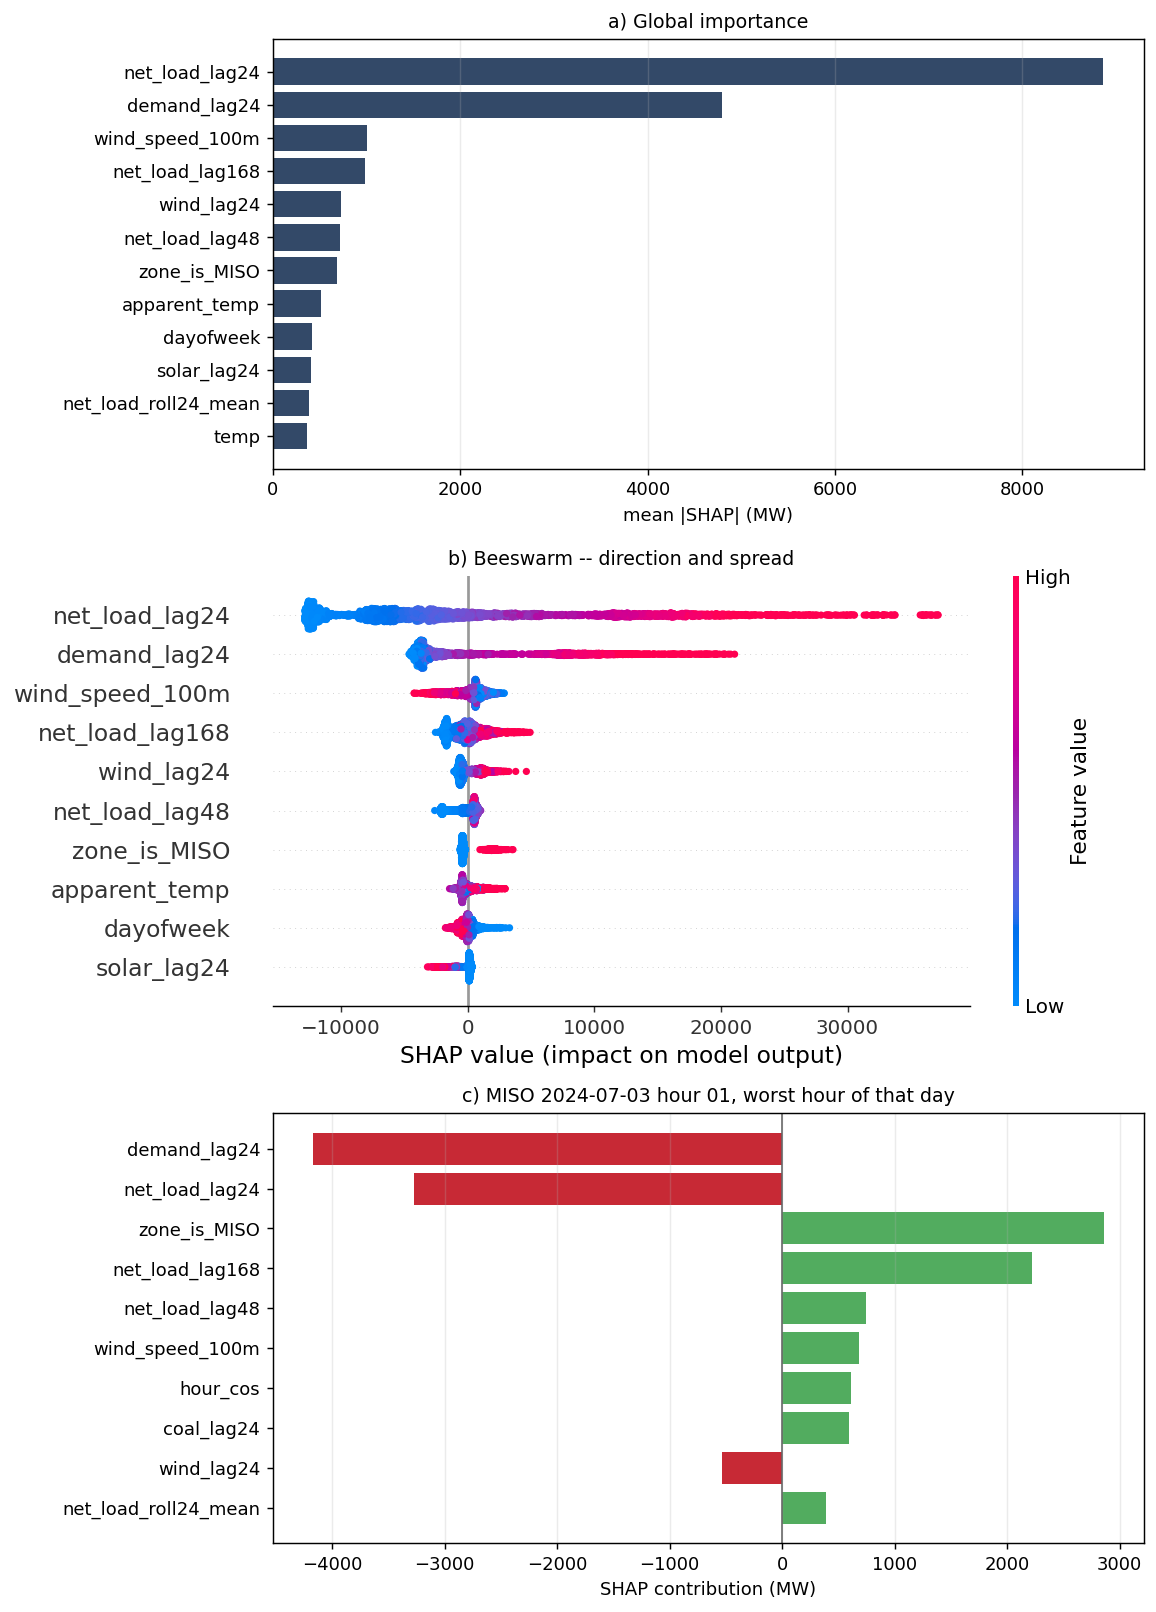


Spearman between permutation rank and mean|SHAP| rank: +0.95


In [5]:
# WHAT: TreeSHAP on the boosting model -- global bar, beeswarm, and the ten largest
#       contributions to the worst hour of the worst day.
# WHY:  SHAP and permutation answer different questions. Permutation measures how
#       much MODEL PERFORMANCE depends on a column; SHAP attributes ONE
#       prediction to its inputs. A feature can be near-zero on permutation and
#       large on SHAP for a specific hour, and neither number is wrong.
# NOTE: applied to the TRANSFORMED matrix, so the labels are `selected_`.
import shap

print("explaining:", WORST)
SHAP_N = min(3000, len(Xh))
shap_idx = np.random.default_rng(cfg.SEED).choice(len(Xh), SHAP_N, replace=False)
Xs = Xh.iloc[shap_idx]

explainer = shap.TreeExplainer(model)
sv = explainer(Xs)
print(f"SHAP on {SHAP_N:,} holdout rows x {Xs.shape[1]} features")

mean_abs = pd.Series(np.abs(sv.values).mean(axis=0), index=Xs.columns).sort_values(
    ascending=False)
print("\ntop 12 by mean |SHAP| (MW)")
print(mean_abs.head(12).to_string(float_format="{:,.1f}".format))

# The worst day, as its own rows, explained one hour at a time.
day_mask = ((hold[cfg.GROUP_COL].to_numpy() == WORST["zone"]) &
            (pd.to_datetime(hold[cfg.TIME_COL]).dt.strftime("%Y-%m-%d").to_numpy()
             == WORST["date"]))
Xday = Xh.loc[day_mask]
sv_day = explainer(Xday)
# SLICE THE PREDICTIONS, NEVER THE FRAME YOU PREDICT ON. `pipe.predict(hold[mask])`
# looks correct and is not: the lag step resolves history by timestamp inside the
# frame it is given, so handing it a single day leaves every lag at t-24, t-48 and
# t-168 outside the frame, imputed, and the output collapses toward the panel mean
# (26,529 MW). Measured on this very day, the sliced call returns 26,551-29,189 MW
# against actuals of 60,305-93,429 and invents a 64,410 MW worst-hour error. `pred`
# was computed once on the whole holdout in 7.1; index into it.
err_all = hold[cfg.TARGET].to_numpy() - pred
err_day = err_all[day_mask]
worst_hour = int(np.argmax(np.abs(err_day)))
print(f"\nworst hour within that day: index {worst_hour}, "
      f"actual - predicted = {err_day[worst_hour]:+,.1f} MW")

fig = plt.figure(figsize=(9.0, 12.5))
ax1 = fig.add_subplot(3, 1, 1)
top12 = mean_abs.head(12).iloc[::-1]
ax1.barh(top12.index, top12.values, color="#1d3557", alpha=0.9)
ax1.set_xlabel("mean |SHAP| (MW)"); ax1.set_title("a) Global importance", fontsize=10.5)
ax1.grid(alpha=0.25, axis="x")

ax2 = fig.add_subplot(3, 1, 2)
plt.sca(ax2)
shap.summary_plot(sv.values, Xs, max_display=10, show=False, plot_size=None,
                  color_bar=True)
ax2.set_title("b) Beeswarm -- direction and spread", fontsize=10.5)

ax3 = fig.add_subplot(3, 1, 3)
contrib = pd.Series(sv_day.values[worst_hour], index=Xday.columns)
print("\nten largest SHAP contributions to that hour (MW):")
print(contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(10)
      .to_string(float_format="{:+,.1f}".format))
_pair = [c for c in ("demand_lag24", "net_load_lag24") if c in contrib.index]
print(f"{' + '.join(_pair)} together: {contrib[_pair].sum():+,.1f} MW")
contrib = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(10).iloc[::-1]
ax3.barh(contrib.index, contrib.values,
         color=["#c1121f" if v < 0 else "#3fa34d" for v in contrib.values], alpha=0.9)
ax3.axvline(0, color="0.4", lw=0.9)
ax3.set_xlabel("SHAP contribution (MW)")
ax3.set_title(f"c) {WORST['zone']} {WORST['date']} hour {worst_hour:02d}, worst hour of that day", fontsize=10.5)
ax3.grid(alpha=0.25, axis="x")
plt.tight_layout()
plt.savefig(cfg.FIGURES / "07_shap.png", bbox_inches="tight")
plt.show()

perm_rank = single.set_index("feature")["mae_increase_mw"].rank(ascending=False)
shap_rank = mean_abs.rank(ascending=False)
both = pd.concat([perm_rank.rename("perm"), shap_rank.rename("shap")], axis=1).dropna()
rho = float(both["perm"].corr(both["shap"], method="spearman"))
print(f"\nSpearman between permutation rank and mean|SHAP| rank: {rho:+.2f}")

**Figure: `07_shap.png`**

**What I see:** The global SHAP ranking agrees with permutation (rank correlation +0.95). `net_load_lag24` averages 8,858 MW of attribution and `demand_lag24` 4,792. Directions are sensible: high `net_load_lag24` pushes the forecast up, and hot hours push `apparent_temp` up (the cooling side of §7.3's U). The worst prediction is MISO at 01:00 UTC on 3 July 2024, in a region-day with MAE 19,681 MW: the model forecast 28,706 MW for an actual 86,183 MW, 57,477 MW too low.

**What it means:** This is a data failure, not a modelling one. Notebook 00 (§0.3) found a 24-hour gap in MISO `demand` starting 2024-07-01 06:00, so this hour's lags point into the gap and were filled by imputation. Across the holdout, 233 of 47,299 rows (0.49%) use at least one imputed lag.

**What I do:** Flag rows whose lags are imputed instead of predicting them silently; dropping the gap rows does not help, because the damaged rows are the later ones whose lags point into the gap. Never read SHAP as causal: it says `demand_lag24` and `net_load_lag24` pulled this prediction down, not that yesterday's load causes today's.

### 7.5 — Cluster explainability

A depth-3 decision tree predicts notebook 05's regime label from weather and calendar features only. Notebook 05 built the labels from the curve shape alone, so this checks whether the regimes can be described in observable terms. The tree is scored by balanced accuracy against chance.

surrogate depth-3 tree, 3 regimes (shares {1: 0.595, 2: 0.214, 0: 0.191})
  plain accuracy    CV 0.541 +/- 0.069  vs majority-class baseline 0.595   <- the WRONG comparison here
  balanced accuracy CV 0.627 +/- 0.085  vs chance 0.333   <- the matching one
  in-sample accuracy 0.551
features: ['temp', 'cloud_cover', 'humidity', 'wind_speed', 'month', 'dayofweek', 'is_weekend']  |  n = 13,069 zone-days

rules
                                                rule  predicts purity    n
temp <= 12.9 AND temp <= 8.59 AND wind_speed <= 14.3         0   0.50 2323
 temp <= 12.9 AND temp <= 8.59 AND wind_speed > 14.3         0   0.31 1214
       temp <= 12.9 AND temp > 8.59 AND month <= 3.5         2   0.45  632
        temp <= 12.9 AND temp > 8.59 AND month > 3.5         0   0.31 1156
 temp > 12.9 AND wind_speed <= 10.2 AND month <= 4.5         2   0.87  427
  temp > 12.9 AND wind_speed <= 10.2 AND month > 4.5         2   0.40 3286
  temp > 12.9 AND wind_speed > 10.2 AND temp <= 18.9         1  

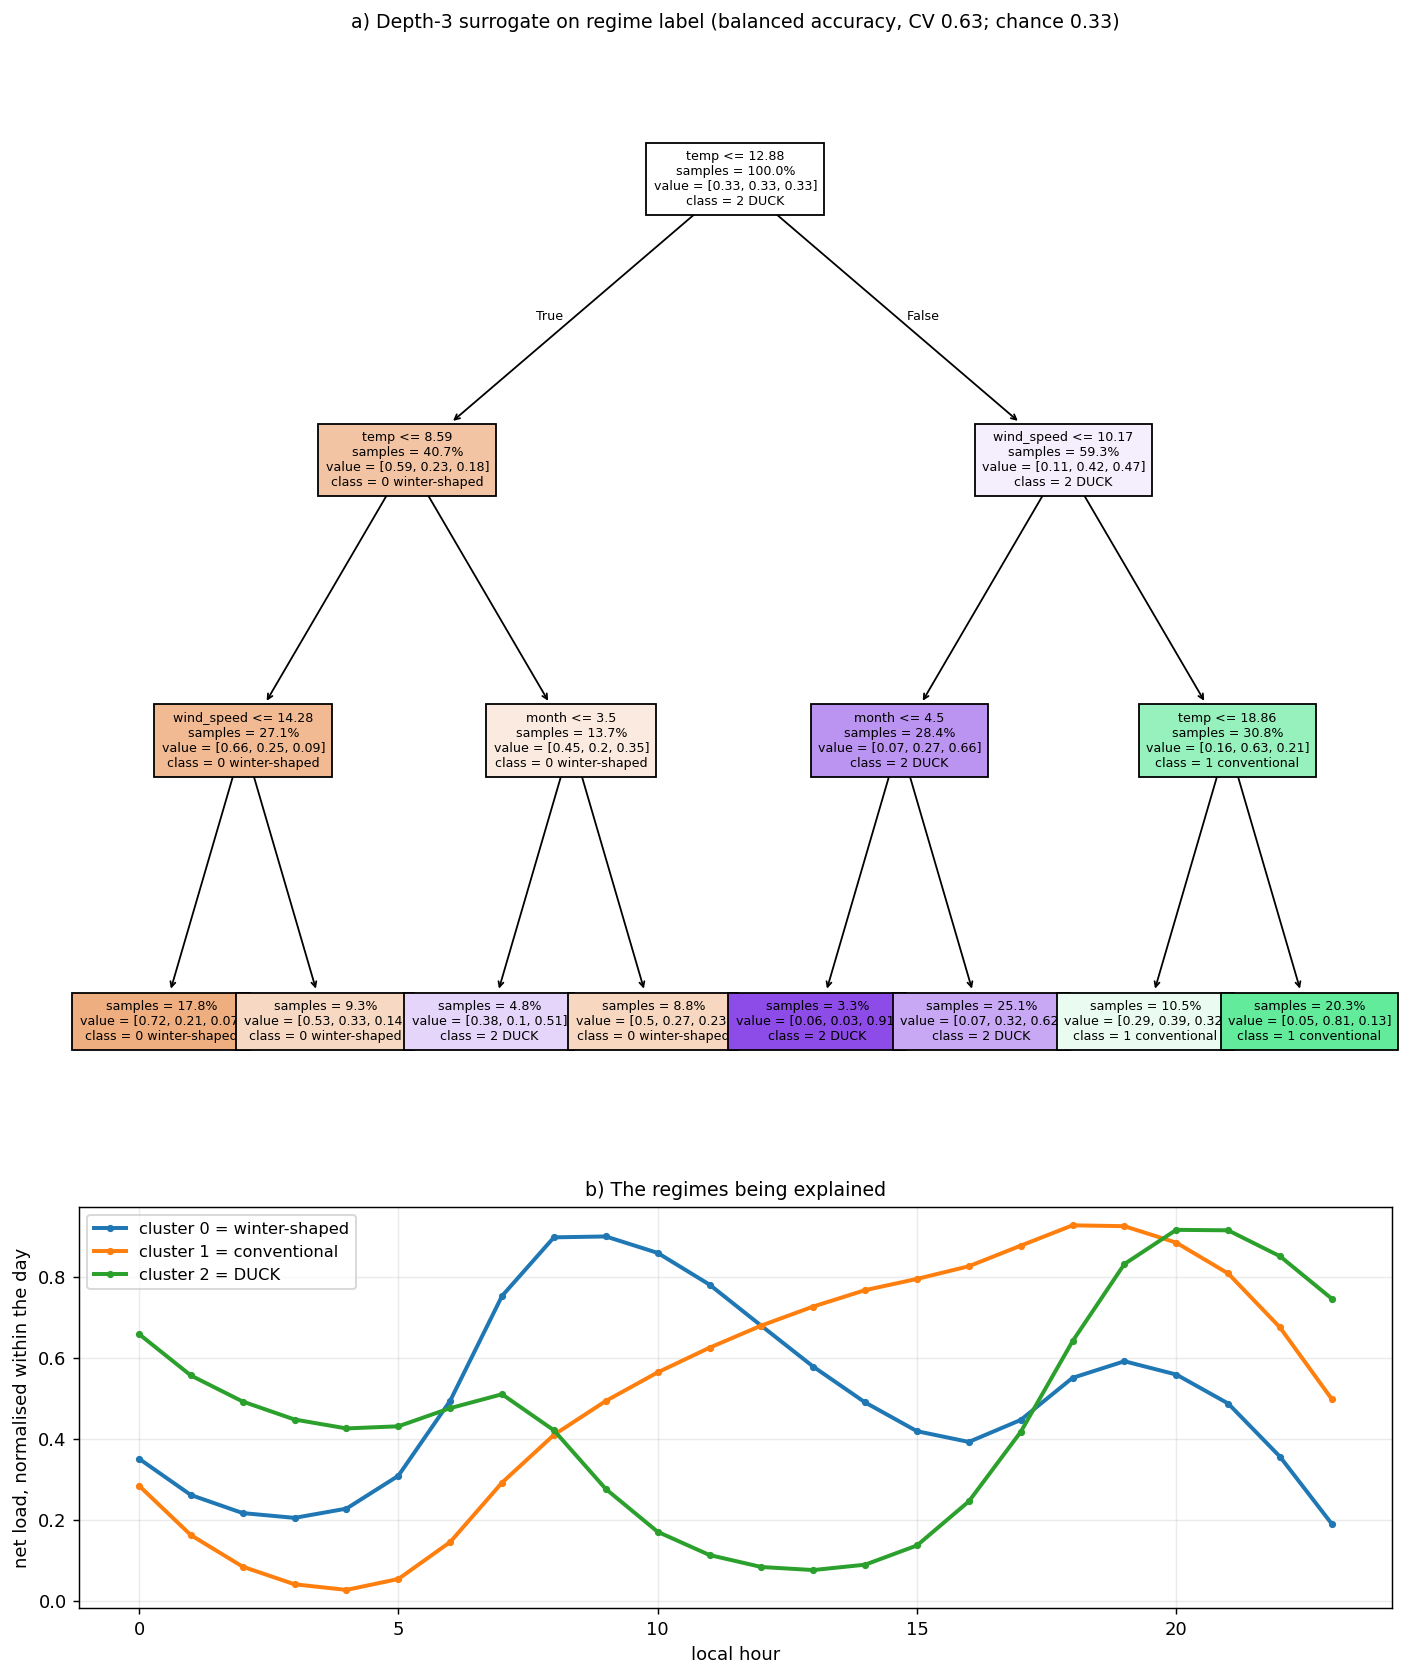


mean feature value by regime
         temp  cloud_cover  humidity  wind_speed  month  dayofweek  is_weekend
cluster                                                                       
0        6.18        59.64     72.03       12.13   5.57       2.90        0.24
1       16.45        52.23     68.15       13.36   6.84       2.95        0.28
2       16.46        38.36     63.59        9.70   6.50       3.20        0.34


In [6]:
# WHAT: a depth-3 tree predicting notebook 05's regime label from calendar and
#       weather only, plus the centroid deltas that name each regime.
# WHY:  this is what turns "cluster 1" into "a high-solar day in spring". A tree
#       that cannot predict the label means the regimes are not describable in
#       the terms available, which would itself be the finding.
# NOTE: the surrogate explains the CLUSTERING, not the forecast, and its accuracy
#       against the cluster labels is the only thing licensing its rules.
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score

shapes = P.daily_shape_matrix(df)
clu = P.make_clustering_pipeline(
    n_components=int(R.require("nb05", "chosen_pcs")),
    algorithm=str(R.require("nb05", "chosen_algorithm")),
    k=int(R.require("nb05", "chosen_param"))).fit(shapes)
labels = pd.Series(clu.named_steps["clust"].labels_, index=shapes.index, name="cluster")

# LOCAL date: the labels are keyed by it (daily_shape_matrix). On the UTC date the
# weather of the first 5-8 hours of every day was averaged into the wrong regime.
daily = (df.assign(date=P.local_calendar_date(df))
           .groupby([cfg.GROUP_COL, "date"])
           .agg(temp=("temp", "mean"), cloud_cover=("cloud_cover", "mean"),
                humidity=("humidity", "mean"), wind_speed=("wind_speed", "mean")))
daily["month"] = daily.index.get_level_values("date").month
daily["dayofweek"] = daily.index.get_level_values("date").dayofweek
daily["is_weekend"] = (daily["dayofweek"] >= 5).astype(int)

feat = daily.reindex(labels.index).dropna()
lab = labels.reindex(feat.index)
# MATCH THE METRIC TO THE TRAINING OBJECTIVE. The regimes are imbalanced -- about
# 59 / 21 / 19 -- and this tree is fitted with class_weight="balanced", which asks
# it to do equally well on all three. Scoring that with PLAIN accuracy compares it
# against a majority-class baseline it was never trying to beat, and a working
# surrogate then reads as a failure: 0.541 against a 0.595 baseline. Balanced
# accuracy is the matching metric, and against its own baseline -- chance, 1/3 for
# three classes -- the same tree scores 0.627. Both are reported, each beside the
# baseline it should be read against, because quoting either alone misleads.
_mk = lambda: DecisionTreeClassifier(max_depth=3, random_state=cfg.SEED,
                                     class_weight="balanced")
_rn = R.require("nb05", "regime_names")        # the derived names, never a typed map
tree = _mk().fit(feat, lab)
acc = float(tree.score(feat, lab))
cv = cross_val_score(_mk(), feat, lab, cv=5)
cv_bal = cross_val_score(_mk(), feat, lab, cv=5, scoring="balanced_accuracy")
base = float(lab.value_counts(normalize=True).max())
chance = 1.0 / lab.nunique()
print(f"surrogate depth-3 tree, {lab.nunique()} regimes "
      f"(shares {dict(lab.value_counts(normalize=True).round(3))})")
print(f"  plain accuracy    CV {cv.mean():.3f} +/- {cv.std():.3f}  "
      f"vs majority-class baseline {base:.3f}   <- the WRONG comparison here")
print(f"  balanced accuracy CV {cv_bal.mean():.3f} +/- {cv_bal.std():.3f}  "
      f"vs chance {chance:.3f}   <- the matching one")
print(f"  in-sample accuracy {acc:.3f}")
print(f"features: {list(feat.columns)}  |  n = {len(feat):,} zone-days")

rules = E.surrogate_rules(tree, feat.columns, X=feat, y=lab)   # purity = share of zone-days, unweighted
print("\nrules")
print(rules.to_string(index=False, formatters={"purity": "{:.2f}".format}))

# WIDER, AND MORE OF IT TO THE TREE. At [2, 1] on a 15.5in canvas every leaf
# box clipped its own `value = [...]` array mid-number, which is the one part of
# a surrogate tree a reader actually needs.
fig, (axa, axb) = plt.subplots(2, 1, figsize=(11.0, 13.0),
                               gridspec_kw={"height_ratios": [2.8, 1]})
plot_tree(tree, feature_names=list(feat.columns),
          class_names=[f"{c} {_rn[str(c)]}" for c in sorted(lab.unique())],
          filled=True, impurity=False, fontsize=7, ax=axa, proportion=True, precision=2)
axa.set_title(f"a) Depth-3 surrogate on regime label (balanced accuracy, CV {cv_bal.mean():.2f}; chance {chance:.2f})", fontsize=10.5)

centro = shapes.groupby(lab).mean()
for c, row in centro.iterrows():
    axb.plot(row.index, row.values, lw=2.2, marker="o", ms=3, label=f"cluster {c} = {_rn[str(c)]}")
axb.set_xlabel("local hour"); axb.set_ylabel("net load, normalised within the day")
axb.set_title("b) The regimes being explained", fontsize=10.5)
axb.legend(fontsize=9); axb.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "07_cluster_tree.png", bbox_inches="tight")
plt.show()

by_cluster = feat.groupby(lab).mean()
print("\nmean feature value by regime")
print(by_cluster.to_string(float_format="{:,.2f}".format))

**Figure: `07_cluster_tree.png`**

**What I see:** The tree splits first on temperature at 12.9 °C, then on temperature, wind speed or month. Cold, light-wind days are called regime 0 (winter-shaped), warm light-wind days regime 2 (duck), warm windy days regime 1 (conventional). Regime 0 averages 6.2 °C against about 16.5 °C for the others; regime 2 has the clearest skies (38% cloud cover against 52% and 60%). Plain accuracy is 0.541, below the 0.595 majority baseline, but the tree uses balanced class weights, and its balanced accuracy is 0.627 against chance 0.333.

**What it means:** The regimes have weather signatures, but only the cold one holds within regions (notebook 05 §5.4c, five of five). The duck's sunny signature is mostly geography: 77% of duck days are CISO's. Balanced accuracy of 0.63 is well above chance but far from reliable, so weather describes the regimes, it does not determine them.

**What I do:** Report balanced accuracy 0.627 against 0.333, with plain accuracy and its baseline beside it. A depth-3 tree explains the clustering, not the forecast.

### 7.6 — What these attributions do and do not license

1. **Credit among exact substitutes is partly arbitrary.** Since `net_load_lag24 = demand_lag24 − wind_lag24 − solar_lag24`, how credit is split between them depends on which column the trees used. The family and ablation views of §7.2 are safer.
2. **Importance is not causation.** Every attribution describes the fitted model on the observed data, not the effect of an intervention.
3. **Causal questions belong to notebook 03.** Its designs do not agree on one estimate, and the project withholds a causal effect of solar; nothing here overrides that.

In [7]:
R.save("nb07", dict(
    champion_horizon=int(HORIZON),
    champion_lags=[int(v) for v in LAGS],
    holdout_mae_refit=float(mae),
    holdout_mae_nb04=float(reported),
    n_features_explained=int(Xh.shape[1]),
    worst_day=dict(WORST),
    explained_day=f"{WORST['zone']} {WORST['date']}",
    permutation_top10={str(r.feature): float(r.mae_increase_mw)
                       for r in single.head(10).itertuples()},
    permutation_by_family={str(r.family): float(r.mae_increase_mw)
                           for r in grouped.itertuples()},
    grouped_over_sum_ratio={str(r.family): (None if pd.isna(r.ratio_grouped_over_sum)
                                            else float(r.ratio_grouped_over_sum))
                            for r in gap.itertuples()},
    n_free_riders=int(len(free)),
    free_rider_features=[str(f) for f in free["feature"].head(10)],
    pdp_vs_ale=dict(feature=str(focus), pdp_range_mw=float(pdp_range),
                    ale_range_mw=float(ale_range),
                    max_gap_mw=float(disagreement)),
    shap_rows=int(SHAP_N),
    shap_top10={str(k): float(v) for k, v in mean_abs.head(10).items()},
    shap_vs_permutation_spearman=float(rho),
    worst_hour_error_mw=float(err_day[worst_hour]),
    surrogate=dict(depth=3, accuracy_in_sample=float(acc),
                   cv_mean=float(cv.mean()), cv_sd=float(cv.std()),
                   cv_balanced_mean=float(cv_bal.mean()),
                   cv_balanced_sd=float(cv_bal.std()),
                   majority_baseline=float(base),
                   chance_baseline=float(chance),
                   class_weight="balanced",
                   metric_to_read="balanced accuracy against chance",
                   n_zone_days=int(len(feat)),
                   features=[str(c) for c in feat.columns]),
))
print("notebook 07 complete")

notebook 07 complete
